# 05 — Structuration des fenêtres glissantes

Chaque exemple contient 672 pas de 15 minutes, soit 7 jours × 96 pas par jour, et exactement 11 variables : 4 mesures physiques et 7 variables calendaires/cycliques. Le pas entre deux fenêtres est fixé à 96 afin de construire une fenêtre par jour.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.windowing import build_sliding_windows

PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "sinert_features.csv"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TIMESTAMP = "timestamp"
PHYSICAL_FEATURES = [
    "EM_VIRTUAL kWh (kWh) [ABS]",
    "EM_VIRTUAL kvarh (kvarh) [ABS]",
    "EM_VIRTUAL kW dmd (kW) [MAX]",
    "EM_VIRTUAL kVA dmd (kVA) [MAX]",
]
CALENDAR_FEATURES = [
    "hour",
    "day_of_week",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "day_of_week_sin",
    "day_of_week_cos",
]
FEATURE_COLUMNS = [*PHYSICAL_FEATURES, *CALENDAR_FEATURES]
TARGET_COLUMN = "EM_VIRTUAL kW sys (kW) [AVG]"
WINDOW_SIZE = 672
STEPS_PER_DAY = 96
STRIDE = STEPS_PER_DAY
HORIZON = 1

df = pd.read_csv(PROCESSED_PATH, parse_dates=[TIMESTAMP])
df = df.sort_values(TIMESTAMP).reset_index(drop=True)
missing_features = df[FEATURE_COLUMNS].isna().sum()
if missing_features.any():
    raise ValueError(f"Valeurs manquantes dans les caractéristiques : {missing_features[missing_features > 0].to_dict()}")
print(f"Lignes disponibles : {len(df):,}")
print(f"Variables caractéristiques : {len(FEATURE_COLUMNS)}")
print("Ordre des variables :", FEATURE_COLUMNS)


Lignes disponibles : 127,184
Variables caractéristiques : 11
Ordre des variables : ['EM_VIRTUAL kWh (kWh) [ABS]', 'EM_VIRTUAL kvarh (kvarh) [ABS]', 'EM_VIRTUAL kW dmd (kW) [MAX]', 'EM_VIRTUAL kVA dmd (kVA) [MAX]', 'hour', 'day_of_week', 'is_weekend', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos']


## Construction des fenêtres

Une fenêtre qui traverse un trou temporel est ignorée. La cible sauvegardée séparément correspond à la puissance active moyenne du pas suivant (`horizon=1`), pour permettre l'entraînement ultérieur d'un modèle de prévision.

In [2]:
X, y, window_metadata = build_sliding_windows(
    df,
    feature_columns=FEATURE_COLUMNS,
    timestamp_column=TIMESTAMP,
    window_size=WINDOW_SIZE,
    stride=STRIDE,
    horizon=HORIZON,
    target_column=TARGET_COLUMN,
)

if X.shape[2] != 11 or X.shape[1] != 672:
    raise AssertionError(f"Shape inattendue : {X.shape}")

windows_path = OUTPUT_DIR / "sinert_windows_672.npz"
metadata_path = OUTPUT_DIR / "sinert_windows_672_metadata.csv"
spec_path = OUTPUT_DIR / "sinert_windows_672_spec.json"
np.savez_compressed(windows_path, X=X, y=y)
window_metadata.to_csv(metadata_path, index=False)
specification = {
    "feature_columns": FEATURE_COLUMNS,
    "physical_features": PHYSICAL_FEATURES,
    "calendar_features": CALENDAR_FEATURES,
    "target_column": TARGET_COLUMN,
    "window_size_steps": WINDOW_SIZE,
    "steps_per_day": STEPS_PER_DAY,
    "context_days": WINDOW_SIZE // STEPS_PER_DAY,
    "stride_steps": STRIDE,
    "horizon_steps": HORIZON,
    "X_shape": list(X.shape),
    "y_shape": list(y.shape),
    "dtype": str(X.dtype),
}
spec_path.write_text(json.dumps(specification, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"X shape : {X.shape}")
print(f"y shape : {y.shape}")
print(f"Fenêtres créées : {len(window_metadata):,}")
print(f"Premier début de fenêtre : {window_metadata['window_start'].min()}")
print(f"Dernier début de fenêtre : {window_metadata['window_start'].max()}")
print(f"Fichier X/y : {windows_path}")


X shape : (1194, 672, 11)
y shape : (1194,)
Fenêtres créées : 1,194
Premier début de fenêtre : 2022-07-05 00:00:00
Dernier début de fenêtre : 2026-02-21 07:45:00
Fichier X/y : C:\Évaluation approfondie2\data\processed\sinert_windows_672.npz


## Contrôle visuel d'une fenêtre de sept jours

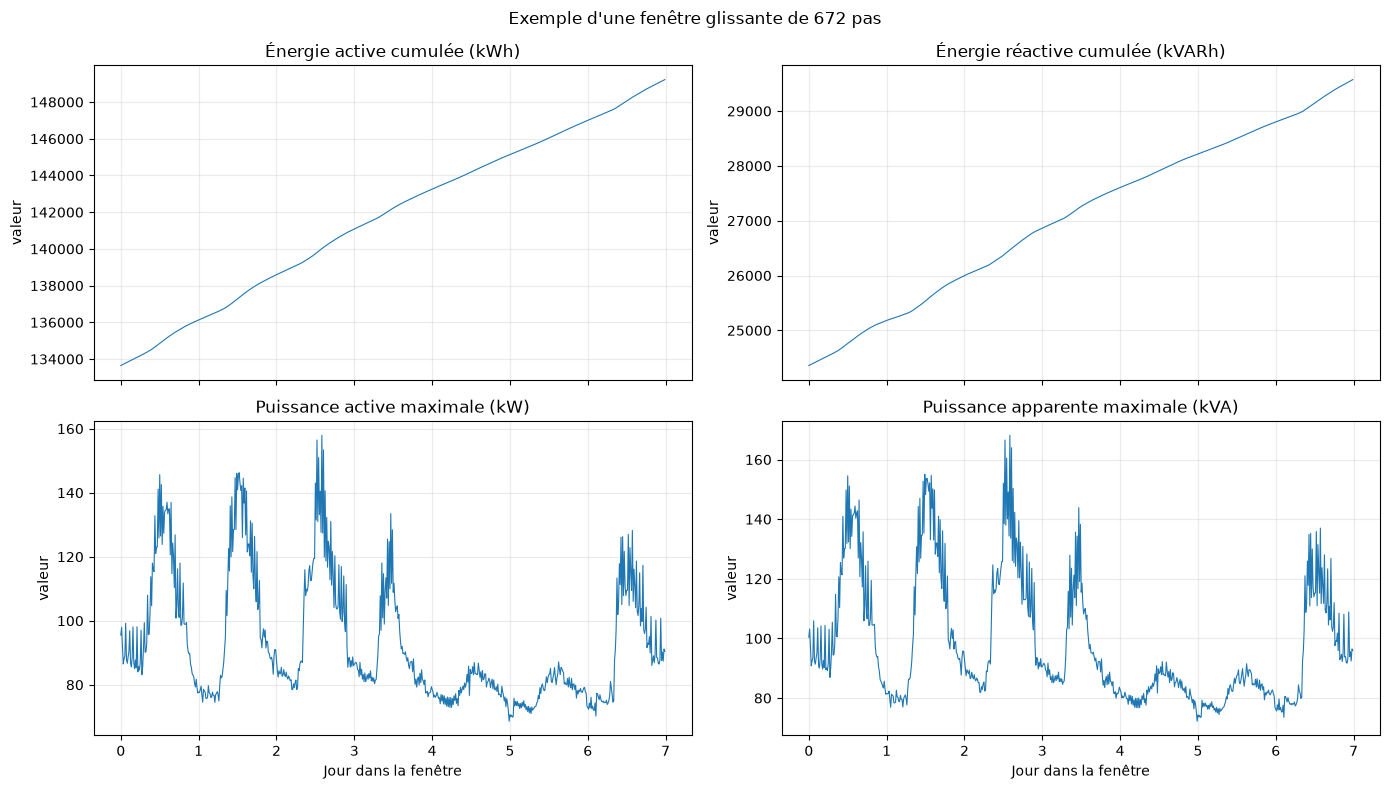

In [3]:
if len(X) > 0:
    elapsed_days = np.arange(WINDOW_SIZE) / STEPS_PER_DAY
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    titles = [
        (PHYSICAL_FEATURES[0], "Énergie active cumulée (kWh)"),
        (PHYSICAL_FEATURES[1], "Énergie réactive cumulée (kVARh)"),
        (PHYSICAL_FEATURES[2], "Puissance active maximale (kW)"),
        (PHYSICAL_FEATURES[3], "Puissance apparente maximale (kVA)"),
    ]
    for axis, (column, title), index in zip(axes.ravel(), titles, range(4)):
        axis.plot(elapsed_days, X[0, :, index], linewidth=0.8)
        axis.set_title(title)
        axis.set_ylabel("valeur")
        axis.grid(alpha=0.25)
    axes[1, 0].set_xlabel("Jour dans la fenêtre")
    axes[1, 1].set_xlabel("Jour dans la fenêtre")
    fig.suptitle("Exemple d'une fenêtre glissante de 672 pas")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "07_fenetre_672_pas_exemple.png", dpi=150)
    plt.show()
    plt.close(fig)
